In [2]:
import pandas as pd
import numpy as np
import seaborn as sb
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

In [3]:
df_timeseries = pd.read_csv(r"D:\Aswini\EDA\EV_charging\evcharging\Data\EVChargingRecords_Features.csv")

In [4]:
df_timeseries.columns

Index(['Unnamed: 0', 'UserID', 'ChargerID', 'ChargerCompany', 'Location',
       'ChargerType', 'StartDay', 'StartTime', 'EndDay', 'EndTime',
       'StartDatetime', 'EndDatetime', 'Duration', 'Demand',
       'Duration_seconds', 'Duration_minutes', 'Duration_hours', 'is_anomaly',
       'start day', 'start month', 'end day', 'end month', 'year',
       'day_of_week', 'is_weekend', 'time_of_day', 'prev_sessions',
       'HighDemand'],
      dtype='str')

In [5]:
df_timeseries['StartDatetime'] = pd.to_datetime(df_timeseries['StartDatetime'])
df_timeseries.set_index('StartDatetime', inplace=True)

In [6]:
df_timeseries.columns

Index(['Unnamed: 0', 'UserID', 'ChargerID', 'ChargerCompany', 'Location',
       'ChargerType', 'StartDay', 'StartTime', 'EndDay', 'EndTime',
       'EndDatetime', 'Duration', 'Demand', 'Duration_seconds',
       'Duration_minutes', 'Duration_hours', 'is_anomaly', 'start day',
       'start month', 'end day', 'end month', 'year', 'day_of_week',
       'is_weekend', 'time_of_day', 'prev_sessions', 'HighDemand'],
      dtype='str')

In [7]:
# Hourly aggregation (use lowercase 'h')
df_hourly = df_timeseries['Demand'].resample('h').sum()

# Daily aggregation (uppercase 'D' is fine)
df_daily = df_timeseries['Demand'].resample('D').sum()


In [8]:
# aggregation by time of the day like morning afternoon evening and night
daily_period_demand = (
    df_timeseries
    .groupby([df_timeseries.index.date, df_timeseries['time_of_day']])['Demand']
    .sum()
    .unstack(fill_value=0)   
)

print(daily_period_demand.head())


time_of_day  Afternoon  Evening  Morning  Night
2021-09-30       27.68   551.51     0.00   0.00
2021-10-01      919.69   899.81   516.03  98.88
2021-10-02      699.33   920.91   351.87  94.63
2021-10-03      559.93   865.44   367.09  94.69
2021-10-04      552.54   714.92   416.39  84.81


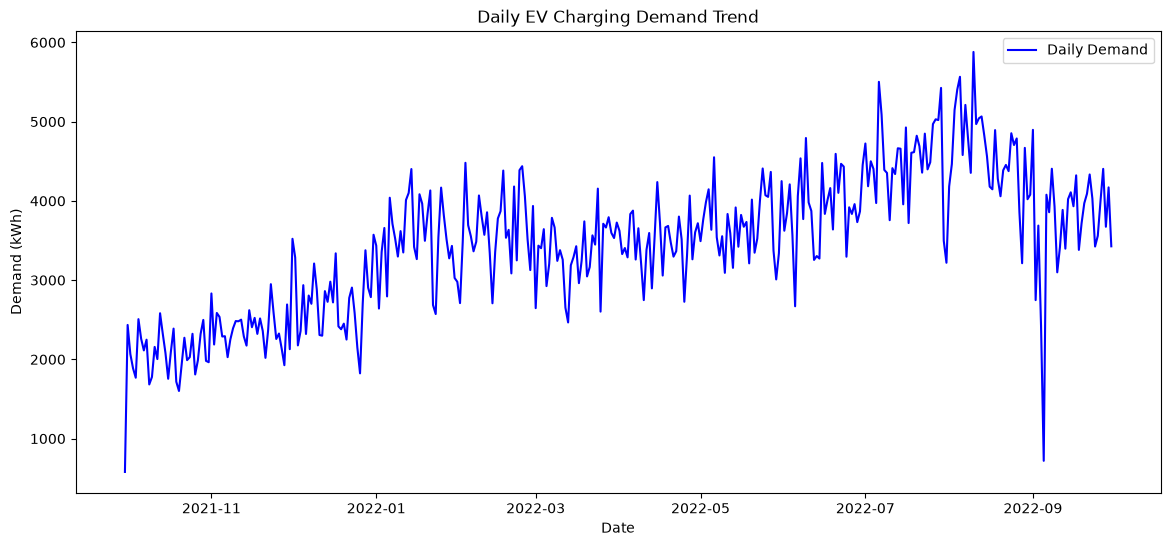

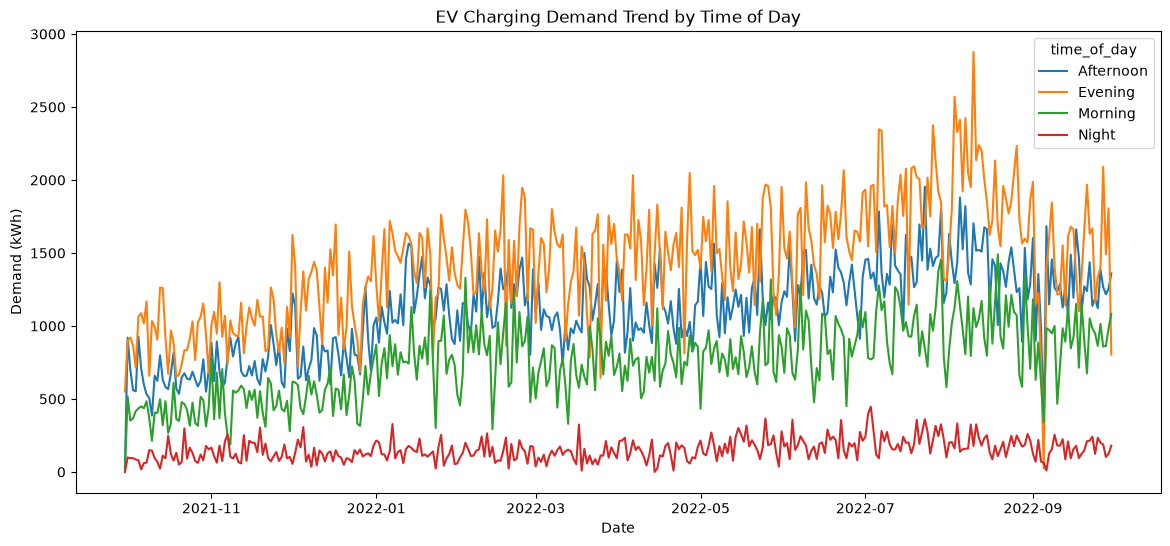

In [9]:
# Plot daily demand
import matplotlib.pyplot as plt
plt.figure(figsize=(14,6))
plt.plot(df_daily.index, df_daily, label='Daily Demand', color='blue')
plt.title("Daily EV Charging Demand Trend")
plt.xlabel("Date")
plt.ylabel("Demand (kWh)")
plt.legend()
plt.show()

# Plot each period’s trend
daily_period_demand.plot(figsize=(14,6))
plt.title("EV Charging Demand Trend by Time of Day")
plt.xlabel("Date")
plt.ylabel("Demand (kWh)")
plt.show()


In [10]:
from statsmodels.tsa.stattools import adfuller

# Stationarity check for overall daily demand
result = adfuller(df_daily.dropna(), result_object=True)
print("Stationarity check for daily demand")
print("ADF Statistic:", result.statistic)
print("p-value:", result.pvalue)

# Stationarity check for each time_of_day demand
print("\nStationarity check for time-of-day demand")
for col in daily_period_demand.columns:
    result = adfuller(daily_period_demand[col].dropna(), result_object=True)
    print(f"{col} -> ADF Statistic: {result.statistic}, p-value: {result.pvalue}")


Stationarity check for daily demand
ADF Statistic: -1.8725163651562768
p-value: 0.34509865323851385

Stationarity check for time-of-day demand
Afternoon -> ADF Statistic: -2.171993233598712, p-value: 0.2165668381584312
Evening -> ADF Statistic: -2.12310327513595, p-value: 0.23532669847737658
Morning -> ADF Statistic: -1.783151134896458, p-value: 0.3888581869630381
Night -> ADF Statistic: -2.4645213167032534, p-value: 0.124346995136698


## Stationarity Analysis Using Augmented Dickey-Fuller (ADF) Test

| Time Series | ADF Statistic | p-value | Stationary? |
|------------|--------------:|---------:|:-----------:|
| Daily Demand | -1.8725 | 0.3451 | ❌ No |
| Morning Demand | -1.7832 | 0.3889 | ❌ No |
| Afternoon Demand | -2.1720 | 0.2166 | ❌ No |
| Evening Demand | -2.1231 | 0.2353 | ❌ No |
| Night Demand | -2.4645 | 0.1243 | ❌ No |

### Interpretation

The Augmented Dickey-Fuller (ADF) test was conducted to assess the stationarity of EV charging demand across the overall daily series and different time-of-day periods. For all series, the p-values were greater than the significance level of 0.05, indicating a failure to reject the null hypothesis of a unit root.

Consequently, the daily demand series and all time-of-day demand series (Morning, Afternoon, Evening, and Night) are **non-stationary**, suggesting the presence of underlying trends, seasonality, or other temporal patterns in EV charging demand.


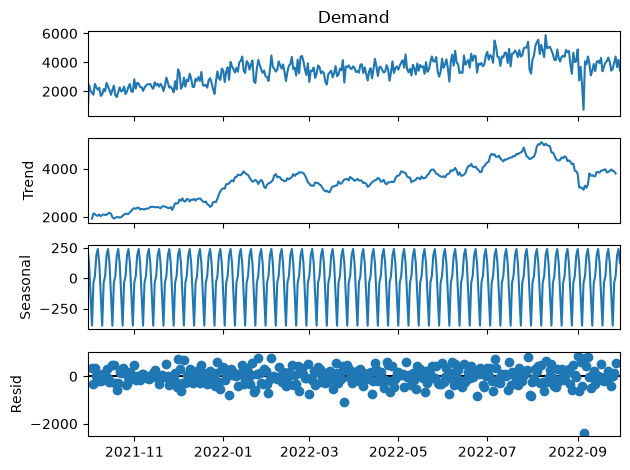

In [11]:
from statsmodels.tsa.seasonal import seasonal_decompose
import matplotlib.pyplot as plt

# Decompose daily demand series
decomp = seasonal_decompose(df_daily, model='additive', period=7)  # weekly cycle assumed
decomp.plot()
plt.show()


In [12]:
# df_daily is a Series of daily demand
df_daily_ma = df_daily.rolling(window=7).mean()

# Forecast = last moving average value
forecast_ma = df_daily_ma.iloc[-1]
print("Next forecast (Moving Average):", forecast_ma)

# Repeat forecast for next 7 days
import pandas as pd
future_dates = pd.date_range(df_daily.index[-1] + pd.Timedelta(days=1), periods=7, freq='D')
ma_forecast_series = pd.Series([forecast_ma]*7, index=future_dates)

print("\n7-day Moving Average Forecast:")
print(ma_forecast_series)


Next forecast (Moving Average): 3807.5928571428567

7-day Moving Average Forecast:
2022-10-01    3807.592857
2022-10-02    3807.592857
2022-10-03    3807.592857
2022-10-04    3807.592857
2022-10-05    3807.592857
2022-10-06    3807.592857
2022-10-07    3807.592857
Freq: D, dtype: float64


In [13]:
from statsmodels.tsa.holtwinters import SimpleExpSmoothing

# Fit exponential smoothing model
model_es = SimpleExpSmoothing(df_daily, initialization_method="heuristic").fit(
    smoothing_level=0.2, optimized=False
)

# Forecast next 7 days
forecast_es = model_es.forecast(7)
print("\nExponential Smoothing Forecast:")
print(forecast_es)



Exponential Smoothing Forecast:
2022-10-01    3847.332331
2022-10-02    3847.332331
2022-10-03    3847.332331
2022-10-04    3847.332331
2022-10-05    3847.332331
2022-10-06    3847.332331
2022-10-07    3847.332331
Freq: D, dtype: float64


In [14]:
from statsmodels.tsa.holtwinters import ExponentialSmoothing

# Fit Holt-Winters model (weekly seasonality assumed: 7 days)
hw_model = ExponentialSmoothing(
    df_daily, 
    trend='add', 
    seasonal='add', 
    seasonal_periods=7
).fit()

# Forecast next 10 days (you can change to 30, etc.)
forecast_hw = hw_model.forecast(10)

# Print forecast numbers
print("Holt-Winters Forecast (next 10 days):")
print(forecast_hw)


Holt-Winters Forecast (next 10 days):
2022-10-01    3678.744328
2022-10-02    3426.668012
2022-10-03    3791.116917
2022-10-04    3850.493555
2022-10-05    4016.626254
2022-10-06    4054.337668
2022-10-07    3964.659993
2022-10-08    3715.764500
2022-10-09    3463.688184
2022-10-10    3828.137089
Freq: D, dtype: float64


In [15]:
import pandas as pd
from statsmodels.tsa.holtwinters import SimpleExpSmoothing, ExponentialSmoothing

# Forecast horizon
horizon = 7

# Collect results in a dictionary
all_forecasts = {}

for col in daily_period_demand.columns:
    series = daily_period_demand[col].dropna()

    # --- Moving Average ---
    ma_val = series.rolling(window=7).mean().iloc[-1]
    future_dates = pd.date_range(series.index[-1] + pd.Timedelta(days=1), periods=horizon, freq='D')
    ma_forecast = pd.Series([ma_val]*horizon, index=future_dates)

    # --- Exponential Smoothing ---
    model_es = SimpleExpSmoothing(series, initialization_method="heuristic").fit(
        smoothing_level=0.2, optimized=False
    )
    es_forecast = model_es.forecast(horizon)

    # --- Holt-Winters ---
    model_hw = ExponentialSmoothing(series, trend='add', seasonal='add', seasonal_periods=7).fit()
    hw_forecast = model_hw.forecast(horizon)

    # Combine into DataFrame
    combined = pd.DataFrame({
        'Moving Average': ma_forecast,
        'Exponential Smoothing': es_forecast,
        'Holt-Winters': hw_forecast
    })

    all_forecasts[col] = combined

# Print results
for col, df in all_forecasts.items():
    print(f"\n=== Forecasts for {col} ===")
    print(df)


d:\Aswini\EDA\EV_charging\evcharging\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)
d:\Aswini\EDA\EV_charging\evcharging\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)
d:\Aswini\EDA\EV_charging\evcharging\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)
d:\Aswini\EDA\EV_charging\evcharging\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)
d:\Aswini\EDA\EV_charging\evcharging\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information


=== Forecasts for Afternoon ===
            Moving Average  Exponential Smoothing  Holt-Winters
2022-10-01         1256.48             1276.25123   1308.920736
2022-10-02         1256.48             1276.25123   1224.040300
2022-10-03         1256.48             1276.25123   1311.775013
2022-10-04         1256.48             1276.25123   1278.618389
2022-10-05         1256.48             1276.25123   1304.549864
2022-10-06         1256.48             1276.25123   1335.163032
2022-10-07         1256.48             1276.25123   1277.998582

=== Forecasts for Evening ===
            Moving Average  Exponential Smoothing  Holt-Winters
2022-10-01     1441.335714            1448.950659   1326.456337
2022-10-02     1441.335714            1448.950659   1289.717826
2022-10-03     1441.335714            1448.950659   1390.113464
2022-10-04     1441.335714            1448.950659   1471.392113
2022-10-05     1441.335714            1448.950659   1598.905498
2022-10-06     1441.335714            14

d:\Aswini\EDA\EV_charging\evcharging\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)
d:\Aswini\EDA\EV_charging\evcharging\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)


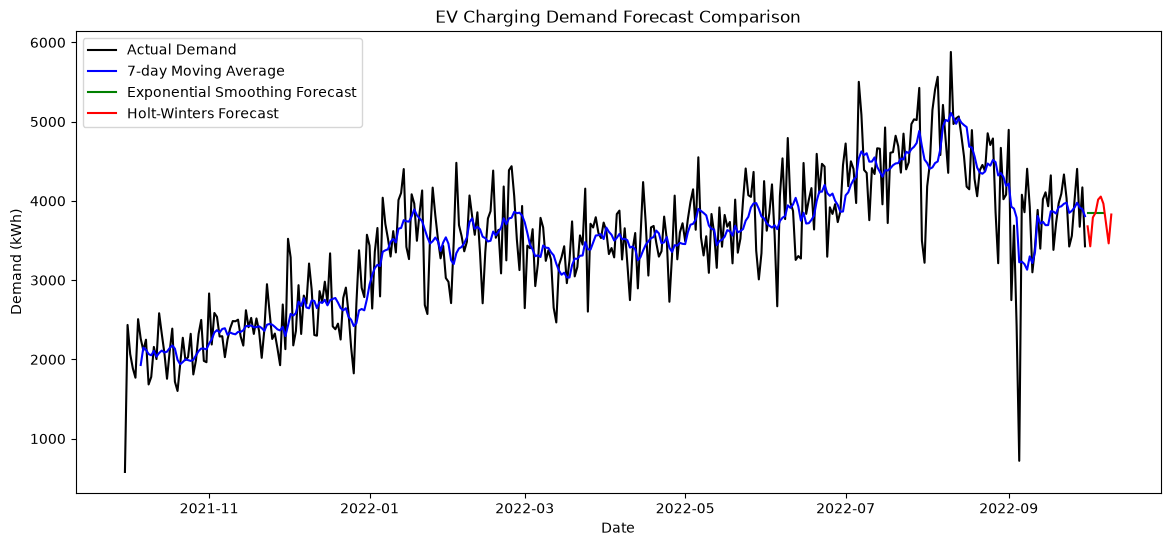

In [16]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14,6))
plt.plot(df_daily.index, df_daily, label='Actual Demand', color='black')
plt.plot(df_daily.index, df_daily.rolling(7).mean(), label='7-day Moving Average', color='blue')
plt.plot(forecast_es.index, forecast_es, label='Exponential Smoothing Forecast', color='green')
plt.plot(forecast_hw.index, forecast_hw, label='Holt-Winters Forecast', color='red')

plt.title("EV Charging Demand Forecast Comparison")
plt.xlabel("Date")
plt.ylabel("Demand (kWh)")
plt.legend()
plt.show()


d:\Aswini\EDA\EV_charging\evcharging\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)
d:\Aswini\EDA\EV_charging\evcharging\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)


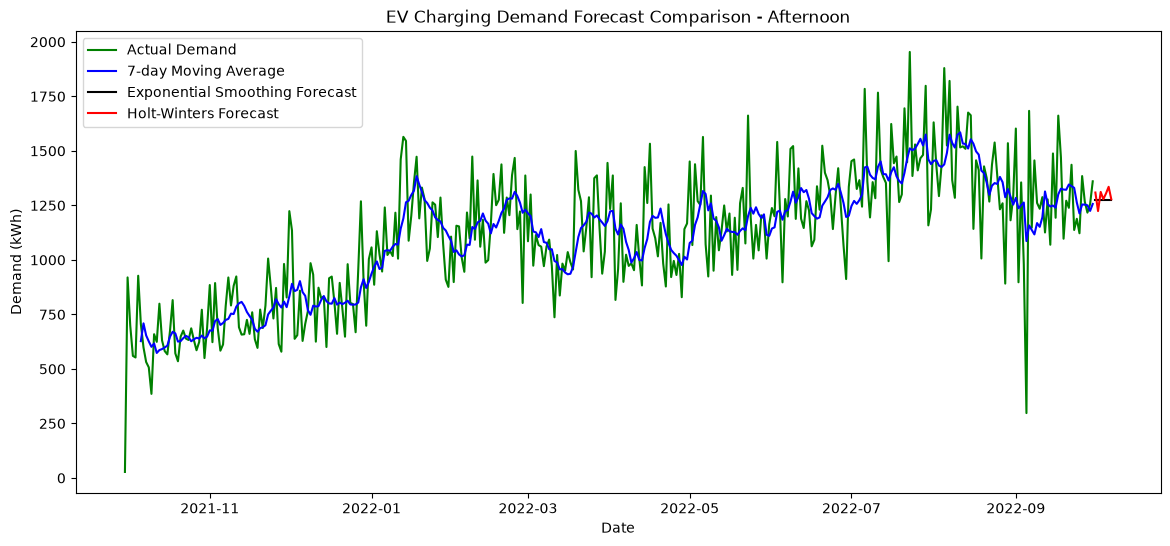

d:\Aswini\EDA\EV_charging\evcharging\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)
d:\Aswini\EDA\EV_charging\evcharging\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)


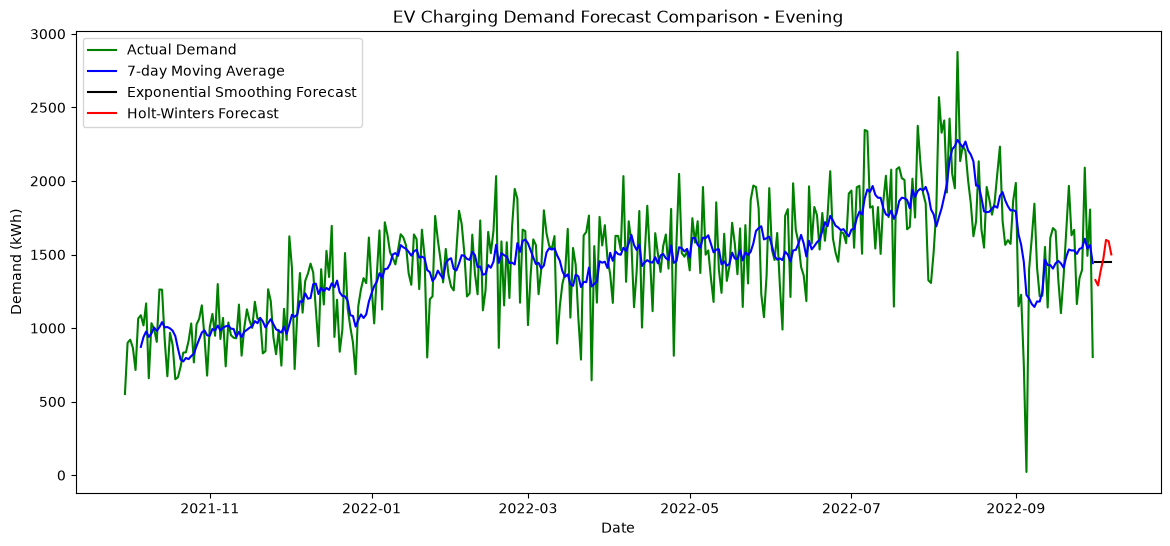

d:\Aswini\EDA\EV_charging\evcharging\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)
d:\Aswini\EDA\EV_charging\evcharging\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)


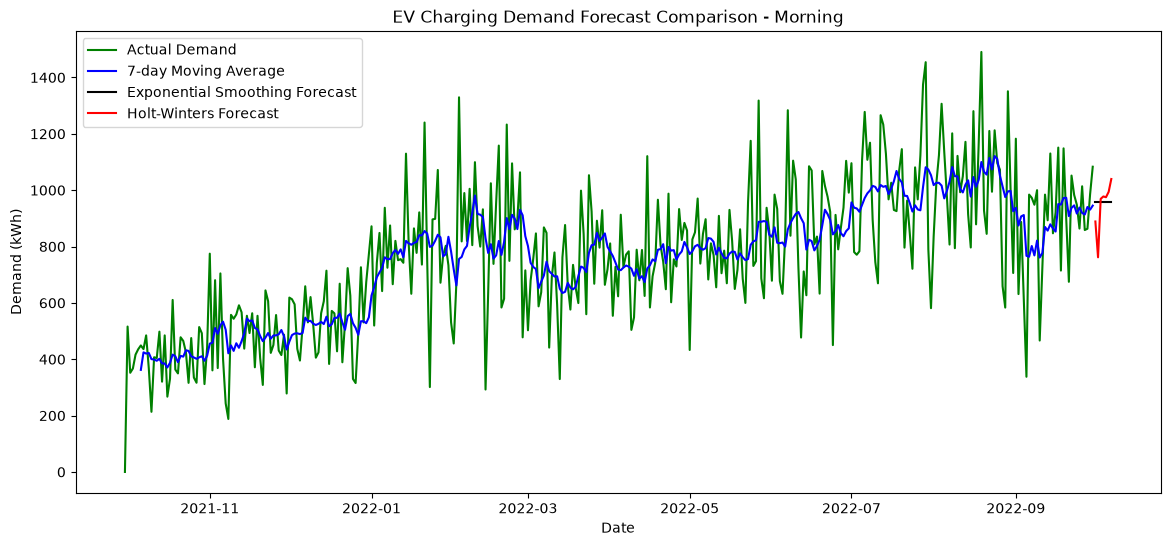

d:\Aswini\EDA\EV_charging\evcharging\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)
d:\Aswini\EDA\EV_charging\evcharging\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)


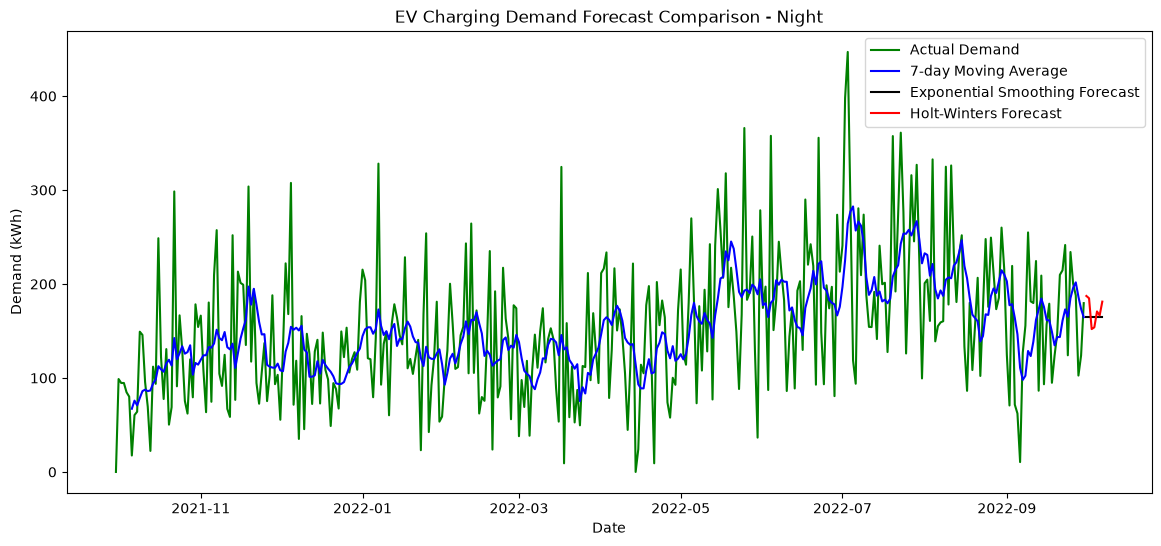

In [17]:
import matplotlib.pyplot as plt
from statsmodels.tsa.holtwinters import SimpleExpSmoothing, ExponentialSmoothing

horizon = 7

for col in daily_period_demand.columns:
    series = daily_period_demand[col].dropna()

    # Moving Average
    ma_val = series.rolling(window=7).mean().iloc[-1]
    future_dates = pd.date_range(series.index[-1] + pd.Timedelta(days=1), periods=horizon, freq='D')
    forecast_ma = pd.Series([ma_val]*horizon, index=future_dates)

    # Exponential Smoothing
    model_es = SimpleExpSmoothing(series, initialization_method="heuristic").fit(
        smoothing_level=0.2, optimized=False
    )
    forecast_es = model_es.forecast(horizon)

    # Holt-Winters
    model_hw = ExponentialSmoothing(series, trend='add', seasonal='add', seasonal_periods=7).fit()
    forecast_hw = model_hw.forecast(horizon)

    # Plot for this period
    plt.figure(figsize=(14,6))
    plt.plot(series.index, series, label='Actual Demand', color='green')
    plt.plot(series.index, series.rolling(7).mean(), label='7-day Moving Average', color='blue')
    plt.plot(forecast_es.index, forecast_es, label='Exponential Smoothing Forecast', color='black')
    plt.plot(forecast_hw.index, forecast_hw, label='Holt-Winters Forecast', color='red')

    plt.title(f"EV Charging Demand Forecast Comparison - {col}")
    plt.xlabel("Date")
    plt.ylabel("Demand (kWh)")
    plt.legend()
    plt.show()


In [18]:
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error
from statsmodels.tsa.holtwinters import SimpleExpSmoothing, ExponentialSmoothing

# Forecast horizon
horizon = 7

# Actual values (last 7 days of demand)
actual = df_daily[-horizon:]

# --- Moving Average ---
ma_val = df_daily.rolling(window=7).mean().iloc[-1]
forecast_ma = pd.Series([ma_val]*horizon, index=actual.index)

mae_ma = mean_absolute_error(actual, forecast_ma)
rmse_ma = np.sqrt(mean_squared_error(actual, forecast_ma))

# --- Exponential Smoothing ---
model_es = SimpleExpSmoothing(df_daily, initialization_method="heuristic").fit(
    smoothing_level=0.2, optimized=False
)
forecast_es = model_es.forecast(horizon)
forecast_es.index = actual.index

mae_es = mean_absolute_error(actual, forecast_es)
rmse_es = np.sqrt(mean_squared_error(actual, forecast_es))

# --- Holt-Winters ---
model_hw = ExponentialSmoothing(df_daily, trend='add', seasonal='add', seasonal_periods=7).fit()
forecast_hw = model_hw.forecast(horizon)
forecast_hw.index = actual.index

mae_hw = mean_absolute_error(actual, forecast_hw)
rmse_hw = np.sqrt(mean_squared_error(actual, forecast_hw))

# Results table
results = pd.DataFrame({
    'Method': ['Moving Average', 'Exponential Smoothing', 'Holt-Winters'],
    'MAE': [mae_ma, mae_es, mae_hw],
    'RMSE': [rmse_ma, rmse_es, rmse_hw]
})

print(results)


                  Method         MAE        RMSE
0         Moving Average  327.757551  357.522563
1  Exponential Smoothing  333.434619  359.724351
2           Holt-Winters  305.986346  348.711594


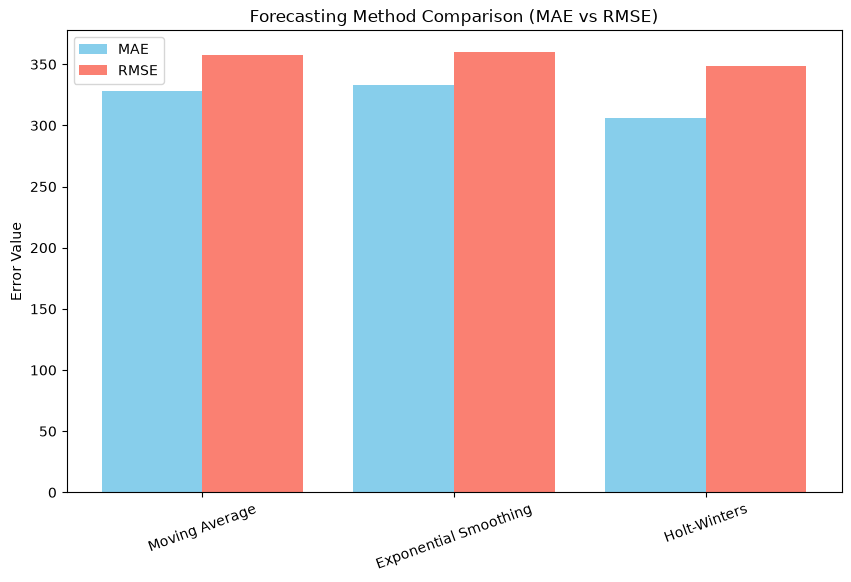

In [19]:
import matplotlib.pyplot as plt

methods = ['Moving Average', 'Exponential Smoothing', 'Holt-Winters']
mae_values = [327.757551, 333.434619, 305.986346]
rmse_values = [357.522563, 359.724351, 348.711594]

x = range(len(methods))

plt.figure(figsize=(10,6))
plt.bar(x, mae_values, width=0.4, label='MAE', color='skyblue')
plt.bar([i+0.4 for i in x], rmse_values, width=0.4, label='RMSE', color='salmon')

plt.xticks([i+0.2 for i in x], methods, rotation=20)
plt.ylabel("Error Value")
plt.title("Forecasting Method Comparison (MAE vs RMSE)")
plt.legend()
plt.show()


In [20]:
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Forecast horizon
horizon = 7

results = []

for col in daily_period_demand.columns:
    series = daily_period_demand[col].dropna()

    # Actual values (last 7 days)
    actual = series[-horizon:]

    # --- Moving Average ---
    ma_val = series.rolling(window=7).mean().iloc[-1]
    forecast_ma = pd.Series([ma_val]*horizon, index=actual.index)

    mae_ma = mean_absolute_error(actual, forecast_ma)
    rmse_ma = np.sqrt(mean_squared_error(actual, forecast_ma))

    # --- Exponential Smoothing ---
    model_es = SimpleExpSmoothing(series, initialization_method="heuristic").fit(
        smoothing_level=0.2, optimized=False
    )
    forecast_es = model_es.forecast(horizon)
    forecast_es.index = actual.index  # align with actual

    mae_es = mean_absolute_error(actual, forecast_es)
    rmse_es = np.sqrt(mean_squared_error(actual, forecast_es))

    # --- Holt-Winters ---
    model_hw = ExponentialSmoothing(series, trend='add', seasonal='add', seasonal_periods=7).fit()
    forecast_hw = model_hw.forecast(horizon)
    forecast_hw.index = actual.index

    mae_hw = mean_absolute_error(actual, forecast_hw)
    rmse_hw = np.sqrt(mean_squared_error(actual, forecast_hw))

    # Collect results
    results.append([col, mae_ma, rmse_ma, mae_es, rmse_es, mae_hw, rmse_hw])

# Build comparison DataFrame
comparison_df = pd.DataFrame(results, columns=[
    'Period', 
    'MAE (MA)', 'RMSE (MA)', 
    'MAE (ES)', 'RMSE (ES)', 
    'MAE (HW)', 'RMSE (HW)'
])

print(comparison_df)


d:\Aswini\EDA\EV_charging\evcharging\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)
d:\Aswini\EDA\EV_charging\evcharging\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)
d:\Aswini\EDA\EV_charging\evcharging\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)
d:\Aswini\EDA\EV_charging\evcharging\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)
d:\Aswini\EDA\EV_charging\evcharging\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information

      Period    MAE (MA)   RMSE (MA)    MAE (ES)   RMSE (ES)    MAE (HW)  \
0  Afternoon   69.325714   85.785816   74.741956   88.034696   79.422675   
1    Evening  303.809388  387.997151  304.897237  388.071871  265.640909   
2    Morning   71.415510   81.267895   72.226838   82.201899   69.985139   
3      Night   40.933469   44.717968   40.933918   44.717968   43.846455   

    RMSE (HW)  
0   85.419969  
1  369.734705  
2   79.859581  
3   48.336965  


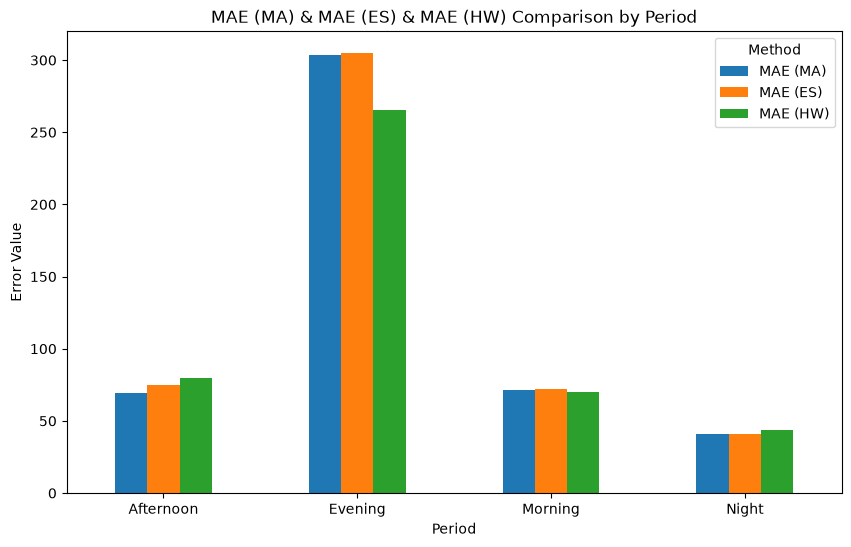

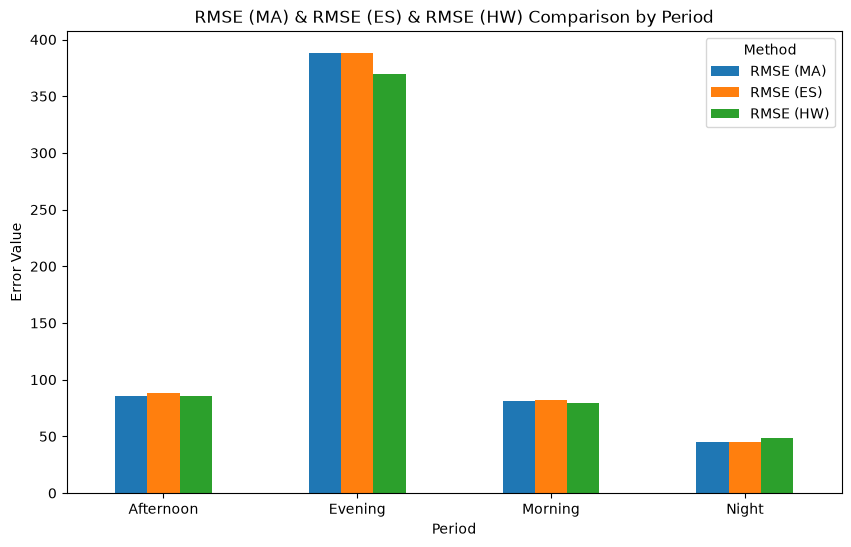

In [21]:
import matplotlib.pyplot as plt

# Use your comparison_df DataFrame
metrics = ['MAE (MA)', 'MAE (ES)', 'MAE (HW)', 'RMSE (MA)', 'RMSE (ES)', 'RMSE (HW)']

for metric_group in [['MAE (MA)', 'MAE (ES)', 'MAE (HW)'], 
                     ['RMSE (MA)', 'RMSE (ES)', 'RMSE (HW)']]:
    comparison_df.plot(
        x='Period', 
        y=metric_group, 
        kind='bar', 
        figsize=(10,6)
    )
    plt.title(f"{' & '.join(metric_group)} Comparison by Period")
    plt.ylabel("Error Value")
    plt.xticks(rotation=0)
    plt.legend(title="Method")
    plt.show()


In [22]:
import pickle
pickle.dump(model_hw, open('timeseries_model.pkl','wb'))

In [23]:

with open('timeseries_model.pkl', 'wb') as file:
    pickle.dump(model_hw, file)